# 108 · MiniVLA v2: replace the token head with a π0-style flow-matching action expert

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, list_episodes, load_episode, show_video
from vlacourse.minivla import MiniVLAFlow, MiniVLAFlowPolicy, MiniVLA, MiniVLAPolicy
from vlacourse import scene_dataset
from vlacourse.torch_data import TableTopDataset

SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

def chunk_frames(eps, ds):
    """(image, instruction, action chunk, state) per frame. Chunks are commanded targets RELATIVE to the gripper pose
    (ds.action_mode == 'rel'), the representation that made every pixel policy in S08 work."""
    out = []
    for i, e in enumerate(eps):
        C = ds.episode_chunks(i)
        for t in range(len(e["action"])):
            out.append((e["front"][t], e["instruction"], C[t], e["state"][t]))
    return out

In [2]:
eps = [load_episode(p) for p in list_episodes(DATA)][:450]
ds = TableTopDataset(DATA, episodes=range(450), horizon=H, use_images=False)
train = chunk_frames(eps, ds)
vla = MiniVLAFlow(np.concatenate([c.reshape(-1, 7) for c in (ds.episode_chunks(i) for i in range(len(eps)))]),
                  np.concatenate([e["state"] for e in eps]), horizon=H, device=device)
print(f"trainable: VLM LoRA + head {sum(p.numel() for p in vla.model.parameters() if p.requires_grad) / 1e6:.1f}M, action expert {sum(p.numel() for p in vla.expert.parameters()) / 1e6:.1f}M")

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 12882.07it/s]

trainable: VLM LoRA + head 31.4M, action expert 4.5M


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


step 100/3363 flow loss 1.164 (21s)


step 200/3363 flow loss 0.877 (40s)


step 300/3363 flow loss 0.613 (60s)


step 400/3363 flow loss 0.557 (81s)


step 500/3363 flow loss 0.509 (101s)


... (24 outputs left out)

step 3000/3363 flow loss 0.154 (589s)


step 3100/3363 flow loss 0.061 (609s)


step 3200/3363 flow loss 0.069 (630s)


step 3300/3363 flow loss 0.103 (649s)


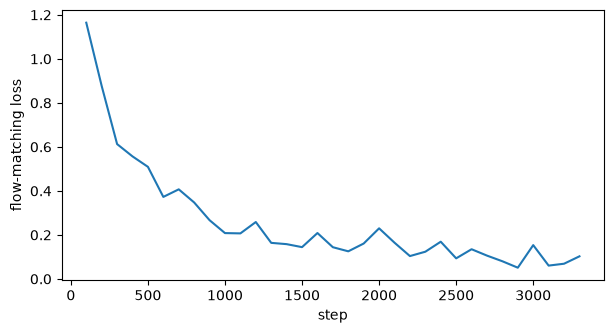

In [3]:
EPOCHS, BS = 3, 16
ckpt = "checkpoints/minivla_flow"
if os.path.exists(ckpt + "/expert.pt"):
    vla.model.load_adapter(ckpt, adapter_name="trained"); vla.model.set_adapter("trained")
    vla.expert.load_state_dict(torch.load(ckpt + "/expert.pt", map_location=device)); log = json.load(open(ckpt + "/log.json"))
else:
    params = vla.parameters()
    opt = torch.optim.AdamW(params, 2e-4)
    total = EPOCHS * (len(train) // BS)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-4, total_steps=total, pct_start=0.05)
    rng, log, step, t0 = np.random.default_rng(0), [], 0, time.time()
    vla.model.train()
    for ep in range(EPOCHS):
        for i in range(0, len(train) - BS + 1, BS):
            b = [train[j] for j in rng.permutation(len(train))[:BS]]
            loss = vla.loss([x[0] for x in b], [x[1] for x in b], np.stack([x[2] for x in b]), np.stack([x[3] for x in b]))
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step(); step += 1
            if step % 100 == 0:
                log.append(dict(step=step, loss=loss.item())); print(f"step {step}/{total} flow loss {loss.item():.3f} ({time.time() - t0:.0f}s)")
    vla.model.save_pretrained(ckpt); torch.save(vla.expert.state_dict(), ckpt + "/expert.pt"); json.dump(log, open(ckpt + "/log.json", "w"))
plt.figure(figsize=(7, 3.5)); plt.plot([l["step"] for l in log], [l["loss"] for l in log]); plt.xlabel("step"); plt.ylabel("flow-matching loss"); plt.show()

In [4]:
vla.model.eval()
env = TableTop(scene=SCENE, cameras=("front",), image_size=(128, 128), seed=0)
t0 = time.time()
pol = MiniVLAFlowPolicy(vla, env, execute=8, steps=10, ds=ds)
res = evaluate(env, pol, n_episodes=30, seed=50_000)
print(f"MiniVLA-flow success {res['success']:.2f} CI [{res['ci'][0]:.2f}, {res['ci'][1]:.2f}] per task {res['per_task']} ({time.time() - t0:.0f}s)")
from vlacourse import showcase as sc
sc.watch(env, pol, seeds=[50_000 + i for i in range(4)], title="108 MiniVLA with a flow action expert")

MiniVLA-flow success 0.53 CI [0.36, 0.70] per task {'pick': 0.5294117647058824, 'place': 0.5384615384615384} (44s)


108 MiniVLA with a flow action expert: 2/4 successful


[True, False, True, False]

In [5]:
obs = env.reset(seed=1)   # latency: same backbone, two action heads
img, ins, st = [obs["images"]["front"]], [env.task["instruction"]], obs["state"][None]
def timeit(fn, n=5):
    fn(); torch.cuda.synchronize() if device == "cuda" else None; t0 = time.time()
    for _ in range(n):
        fn()
    torch.cuda.synchronize() if device == "cuda" else None
    return (time.time() - t0) / n
t_flow = timeit(lambda: vla.predict_chunk(img, ins, st, steps=10))
print(f"flow expert: {t_flow * 1000:.0f} ms per 16-action chunk -> {t_flow / 16 * 1000:.1f} ms per action")
if os.path.exists("../S10_Building_a_VLA/checkpoints/minivla_eval.json"):
    print("token MiniVLA (S10):", json.load(open("../S10_Building_a_VLA/checkpoints/minivla_eval.json")))
print("token head: 7 sequential decoder passes per single action; flow head: 1 prefix pass + 10 small expert passes per 16 actions")

flow expert: 69 ms per 16-action chunk -> 4.3 ms per action
token MiniVLA (S10): {'success': 0.0, 'ci': [0.0, 0.11351339317396876], 'per_task': {'pick': 0.0, 'stack': 0.0, 'place': 0.0}}
token head: 7 sequential decoder passes per single action; flow head: 1 prefix pass + 10 small expert passes per 16 actions
